# Python

In [7]:
import numpy as np
import networkx as nx
import matplotlib as mpl
import matplotlib.pyplot as plt
import importlib
import json
import os

## Visualizing polymers in a 3D lattice

#### Importing full lattice state

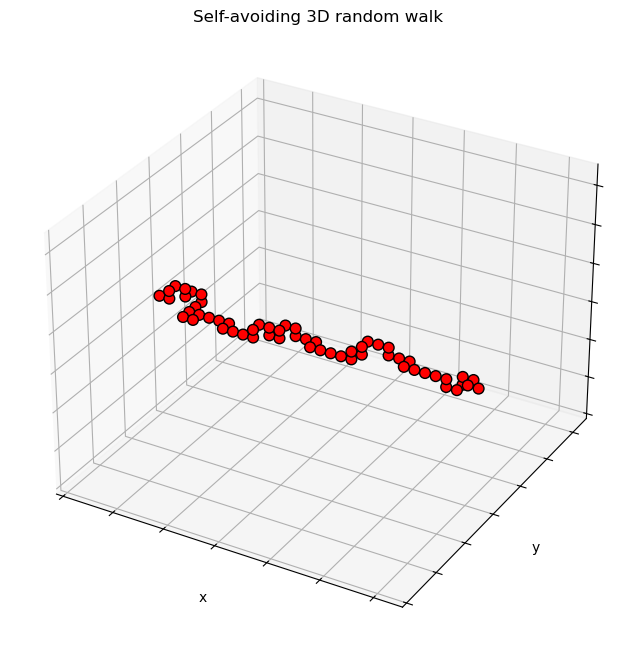

In [20]:
# import json data
dirname = "20251024/testpoly_frame10" 
# dirname = "20250924/testpoly" 
lattice = json.load(open("data/"+dirname+".json"))
lattice = np.array(lattice)

# Get coordinates where array == 1
coords1 = np.argwhere(lattice[..., -1] == 1)
coords2 = np.argwhere(lattice[..., -2] == 1)
x1, y1, z1 = coords1[:, 2], coords1[:, 1], coords1[:, 0]
x2, y2, z2 = coords2[:, 2], coords2[:, 1], coords2[:, 0]

# Scatterplot with circles at sites with a 1
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
# ax.scatter(x1, y1, z1, s=40, c='blue', marker='o', alpha=0.5)
ax.scatter(x2, y2, z2, s=60, c='red', marker='o', edgecolor="black", alpha=1)

# ax.scatter(4,7,8, s=80, c='black', marker='o', alpha=1)

ax.set_title('Self-avoiding 3D random walk')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_xlim(0, lattice.shape[0])
ax.set_ylim(0, lattice.shape[0])
ax.set_zlim(0, lattice.shape[0])
ax.set_xticklabels('')
ax.set_yticklabels('')
ax.set_zticklabels('')
plt.show()

#### Importing species coordinates

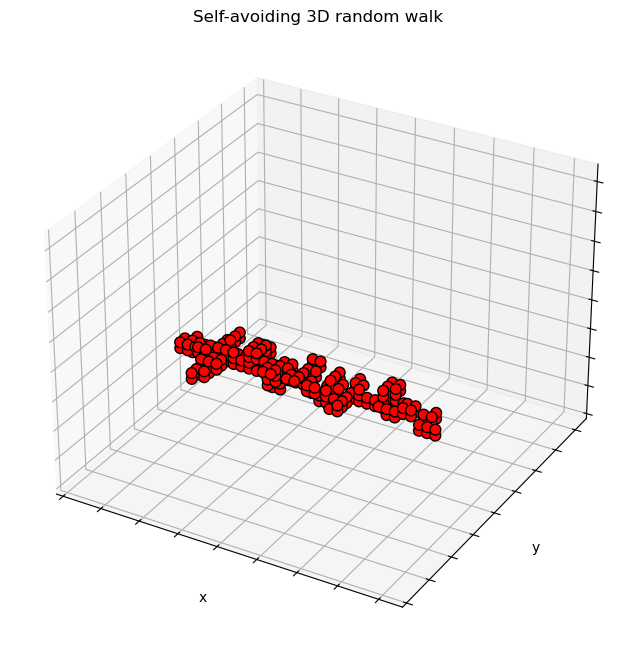

In [26]:
# import json data
dirname = "20251028/testpoly_frame100" 
# dirname = "20250924/testpoly" 
slist = json.load(open("data/"+dirname+".json"))

# Scatterplot with circles at sites with a 1
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

for key, val in slist.items():
    x, y, z = val["coords"] 
    
    if val["name"][:4] == "poly":
        ax.scatter(x, y, z, s=60, c='red', marker='o', edgecolor="black", alpha=1)

# ax.scatter(4,7,8, s=80, c='black', marker='o', alpha=1)

ax.set_title('Self-avoiding 3D random walk')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_xlim(0, slist["1"]["boxlength"])
ax.set_ylim(0, slist["1"]["boxlength"])
ax.set_zlim(0, slist["1"]["boxlength"])
ax.set_xticklabels('')
ax.set_yticklabels('')
ax.set_zticklabels('')
plt.show()

#### Simulation dashboard

In [5]:
def plot_simulation_dashboard(res_or_path, keya, keyb, show=True):
    """
    Plot acceptance rate, gyration radius, Hamiltonian, polymer length vs frames,
    and a 3D scatter of the final polymer configuration.

    res_or_path: dict or path to JSON file produced by the Julia simulation.
    """
    # Load result
    if isinstance(res_or_path, str):
        with open(res_or_path, 'r') as f:
            res_ = json.load(f)
            res = res_[str(keya)][str(keyb)]
    else:
        res = res_or_path[str(keya)][str(keyb)]

    # Safely extract arrays
    def to_np(key):
        arr = np.array(res.get(key, []))
        return arr
    
    print("Species name: ", res["species_name"])
    print("Parameter 1: ", res["alpha"])
    print("Parameter 2: ", res["beta"])

    gyr = to_np("gyration_radius")
    plen = to_np("polymer_length")
    ham = to_np("hamiltonian")
    acc = to_np("acceptance_rate")

    n = max(len(gyr), len(plen), len(ham), len(acc))
    frames = np.arange(1, n + 1)

    fig = plt.figure(figsize=(14, 8))
    gs = fig.add_gridspec(2, 3, height_ratios=[1, 1])

    # Time series
    ax_acc = fig.add_subplot(gs[0, 0])
    ax_gyr = fig.add_subplot(gs[0, 1])
    ax_ham = fig.add_subplot(gs[0, 2])
    ax_len = fig.add_subplot(gs[1, 0])

    if len(acc):
        ax_acc.plot(frames[:len(acc)], acc, color='C0')
    ax_acc.set_title('Acceptance rate')
    ax_acc.set_xlabel('Frame')
    ax_acc.set_ylabel('Rate')
    ax_acc.grid(True, alpha=0.3)
    ax_acc.set_xscale('log')

    if len(gyr):
        ax_gyr.plot(frames[:len(gyr)], gyr, color='C1')
    ax_gyr.set_title('Gyration radius')
    ax_gyr.set_xlabel('Frame')
    ax_gyr.set_ylabel('Radius')
    ax_gyr.grid(True, alpha=0.3)
    ax_gyr.set_xscale('log')

    if len(ham):
        ax_ham.plot(frames[:len(ham)], ham, color='C2')
    ax_ham.set_title('Hamiltonian')
    ax_ham.set_xlabel('Frame')
    ax_ham.set_ylabel('Energy')
    ax_ham.grid(True, alpha=0.3)
    ax_ham.set_xscale('log')
    ax_ham.set_yscale('log')

    if len(plen):
        ax_len.plot(frames[:len(plen)], plen, color='C3')
    ax_len.set_title('Polymer length')
    ax_len.set_xlabel('Frame')
    ax_len.set_ylabel('Length')
    ax_len.grid(True, alpha=0.3)
    ax_len.set_xscale('log')

    # 3D final configuration
    ax3d = fig.add_subplot(gs[1, 1:], projection='3d')
    x, y, z = res["final_coordinates"]
    
    ax3d.scatter(x, y, z, s=60, c='red', marker='o', edgecolor='black', alpha=1)

    L = res.get('boxlength', None)
    if L is not None:
        ax3d.set_xlim(0, L)
        ax3d.set_ylim(0, L)
        ax3d.set_zlim(0, L)
    ax3d.set_title('Final polymer configuration')
    ax3d.set_xlabel('x')
    ax3d.set_ylabel('y')
    ax3d.set_zlabel('z')

    plt.tight_layout()
    if show:
        plt.show()
    return fig

Species name:  poly2
Parameter 1:  -0.75
Parameter 2:  1.0


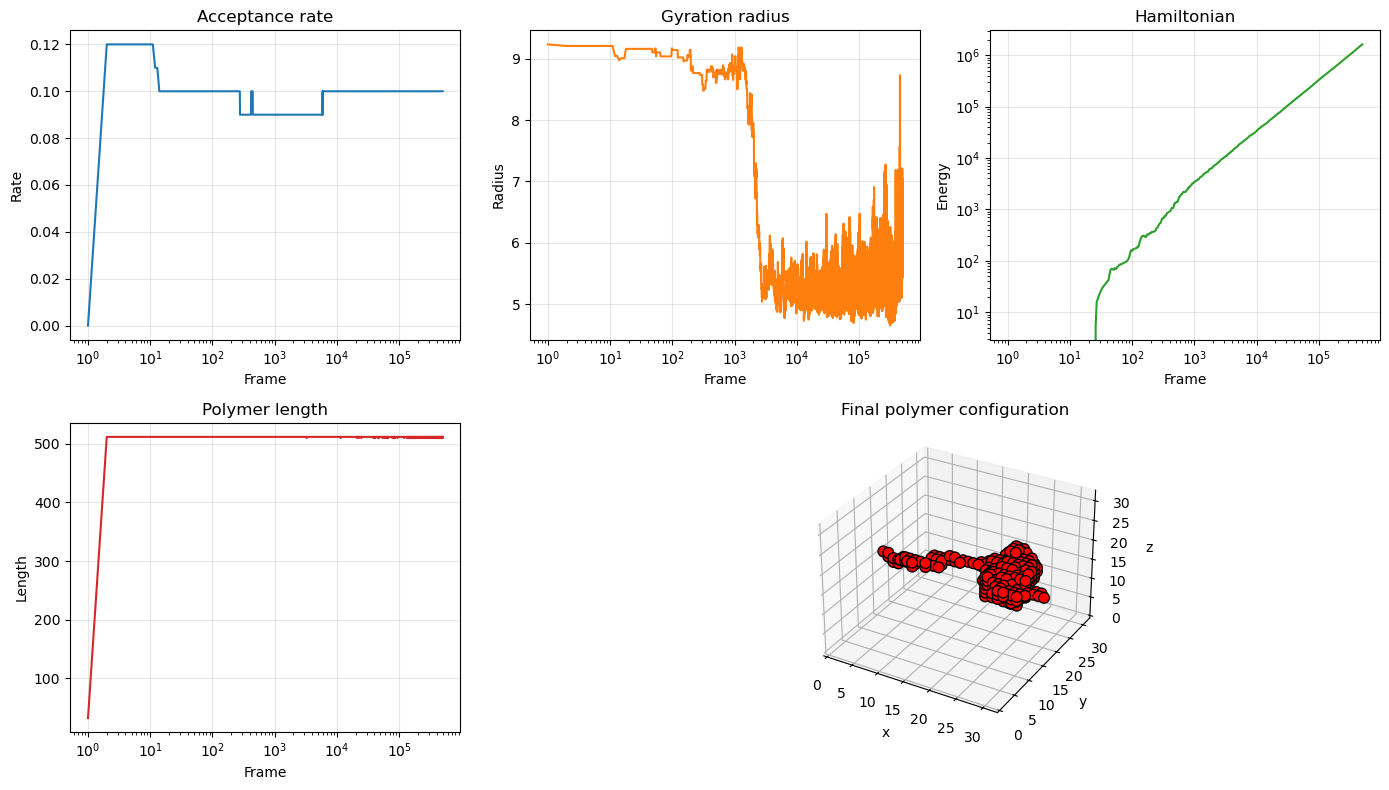

In [6]:
# Example usage:
alpha_index = 2
beta_index = 1
fig = plot_simulation_dashboard('data/20251030/test_cpu{}.json'.format(alpha_index), 
                                alpha_index, beta_index)

## Animations

#### Example

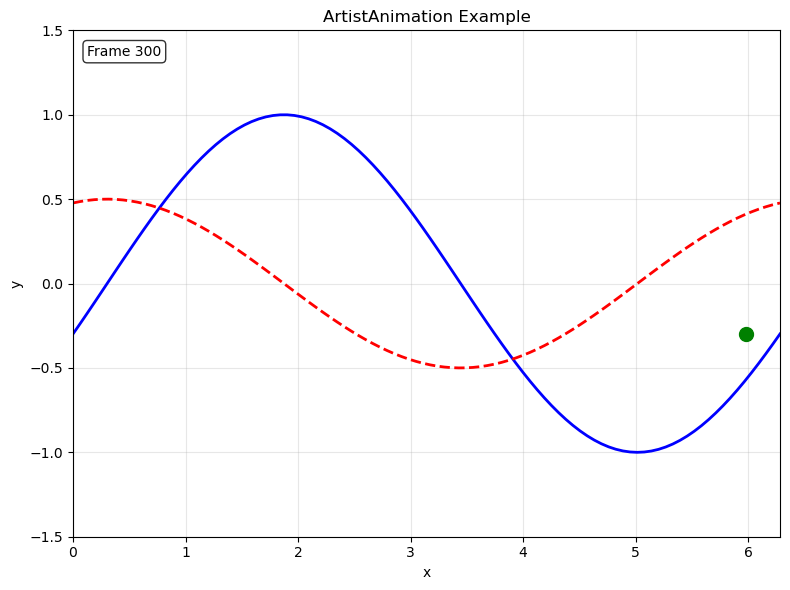

In [ ]:
# Basic example of ArtistAnimation in matplotlib
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# Create figure and axis
fig, ax = plt.subplots(figsize=(8, 6))

# Generate data for animation
x = np.linspace(0, 2*np.pi, 100)
frames = []

# Create a series of artists for each frame
for i in range(300):
    # Create different artists for this frame
    phase = i * 0.02
    y1 = np.sin(x + phase)
    y2 = np.cos(x + phase) * 0.5
    
    # Plot multiple elements as artists
    line1, = ax.plot(x, y1, 'b-', linewidth=2, label='sin wave')
    line2, = ax.plot(x, y2, 'r--', linewidth=2, label='cos wave')
    scatter = ax.scatter([phase], [np.sin(phase)], c='green', s=100, zorder=5)
    text = ax.text(0.02, 0.95, f'Frame {i+1}', transform=ax.transAxes, 
                   bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    # Group all artists for this frame
    frame_artists = [line1, line2, scatter, text]
    frames.append(frame_artists)

# Set up the plot
ax.set_xlim(0, 2*np.pi)
ax.set_ylim(-1.5, 1.5)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('ArtistAnimation Example')
ax.grid(True, alpha=0.3)

# Create animation
anim = animation.ArtistAnimation(fig, frames, interval=100, blit=True, repeat=True)

# Display in notebook
plt.tight_layout()

# Optional: Save as GIF (uncomment if needed)
anim.save('media/sinewaves.gif', writer='pillow', fps=25)

#### Polymer

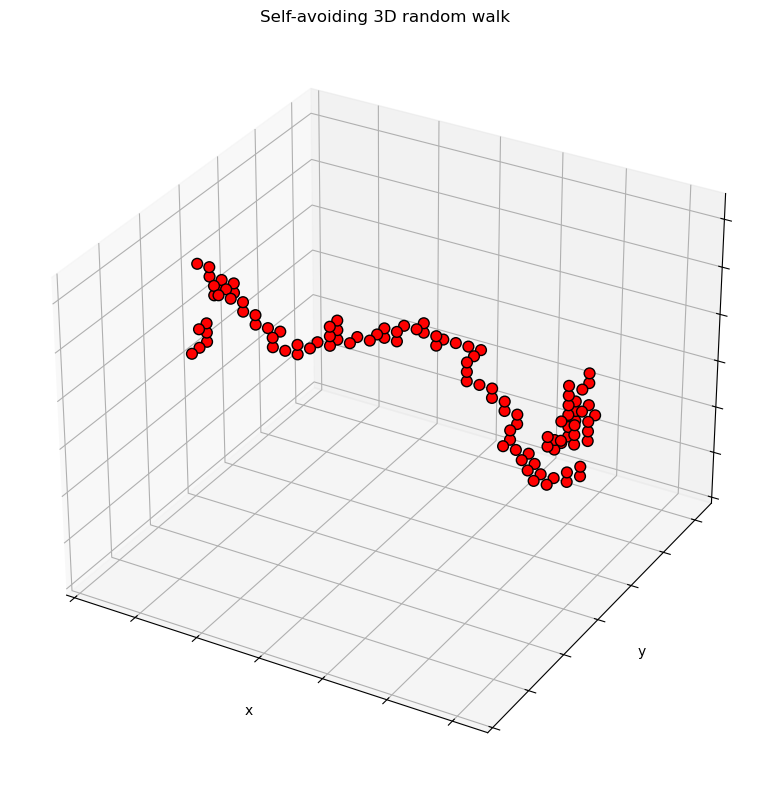

In [42]:
# Scatterplot with circles at sites with a 1
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
dirname = "20251024/testpoly" 

frames = []

for i in range(2000):
    lattice = json.load(open("data/"+dirname+"_frame"+str(i+1)+".json"))
    lattice = np.array(lattice)

    # Get coordinates where array == 1
    coords = np.argwhere(lattice[..., -2] == 1)
    x, y, z = coords[:, 2], coords[:, 1], coords[:, 0]

    scatter = ax.scatter(x, y, z, s=60, c='red', marker='o', edgecolor="black", alpha=1)

    frame_artists = [scatter]
    frames.append(frame_artists)

ax.set_title('Self-avoiding 3D random walk')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_xlim(0, lattice.shape[0])
ax.set_ylim(0, lattice.shape[0])
ax.set_zlim(0, lattice.shape[0])
ax.set_xticklabels('')
ax.set_yticklabels('')
ax.set_zticklabels('')

# Create animation
anim = animation.ArtistAnimation(fig, frames, interval=10, 
                                 blit=True, repeat=True)

# Display in notebook
plt.tight_layout()

anim.save('media/polymer_repulsive.mp4', writer="ffmpeg", fps=25)